In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV



In [2]:
# import the training data

df = pd.read_csv('data/train.csv')

print(f'Training data shape: {df.shape}')
display(df.head())

Training data shape: (8693, 14)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
print("\n---- Data Info ----")
print(df.info())


---- Data Info ----
<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 1.2+ MB
None


In [4]:
print("\n---- Missing Values Analysis ----")
missing_summary = pd.DataFrame({
    'Missing Value Counts' : df.isnull().sum(),
    'Missing Value Percentage' : (df.isnull().sum()/len(df)*100).round(2)
    })

display(missing_summary[missing_summary['Missing Value Counts']>0])

print(f"Columns with no missing values: {missing_summary[missing_summary['Missing Value Counts']==0].index.tolist()}")


---- Missing Values Analysis ----


,Missing Value Counts,Missing Value Percentage
HomePlanet,201,2.31
CryoSleep,217,2.50
Cabin,199,2.29
Destination,182,2.09
Age,179,2.06
VIP,203,2.34
RoomService,181,2.08
FoodCourt,183,2.11
ShoppingMall,208,2.39
Spa,183,2.11


Columns with no missing values: ['PassengerId', 'Transported']


In [5]:
# outlier analysis

numeric_cols = df.select_dtypes(include='float').columns
print(numeric_cols)

Index(['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck'], dtype='str')


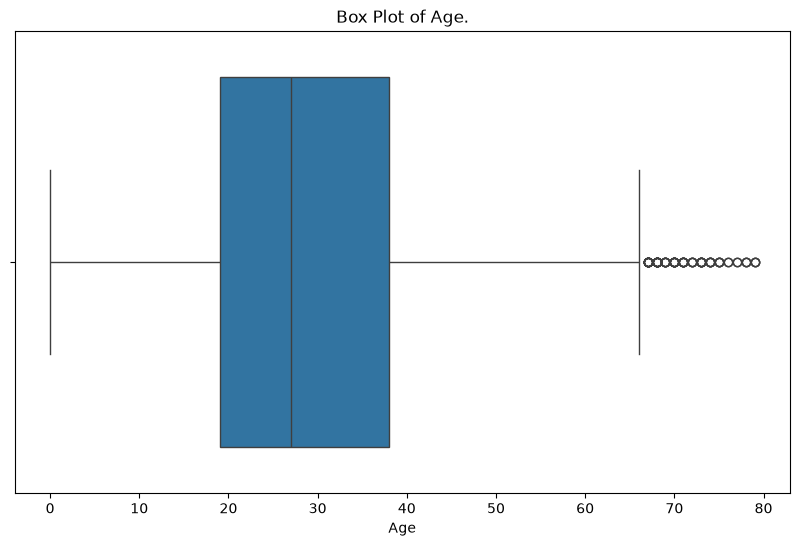

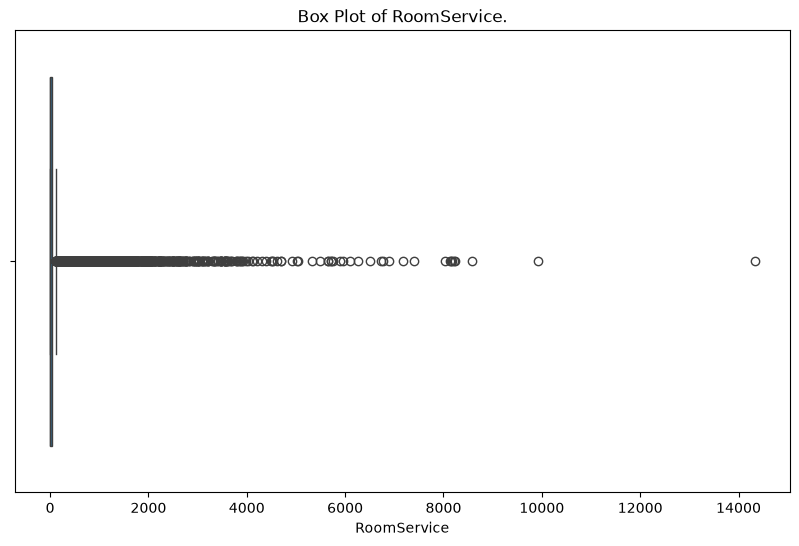

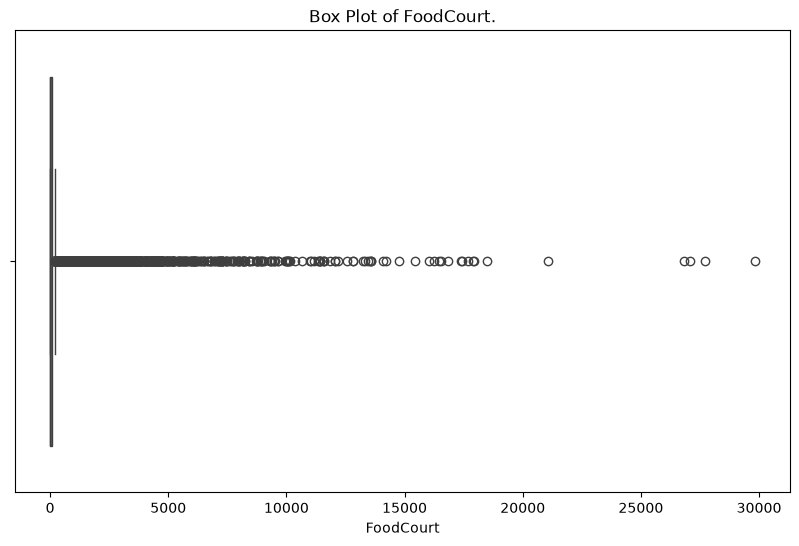

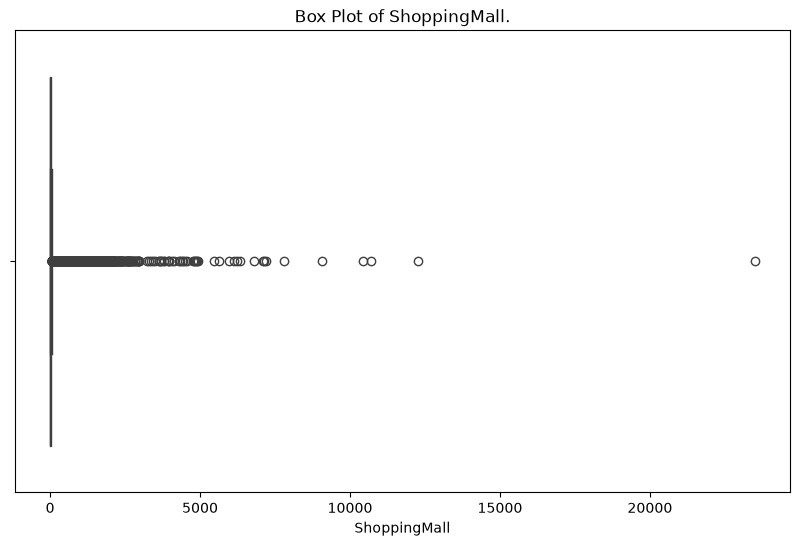

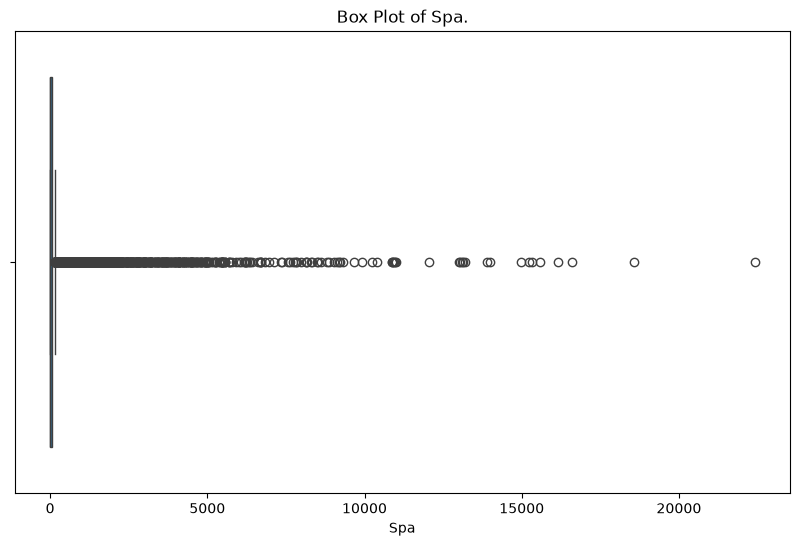

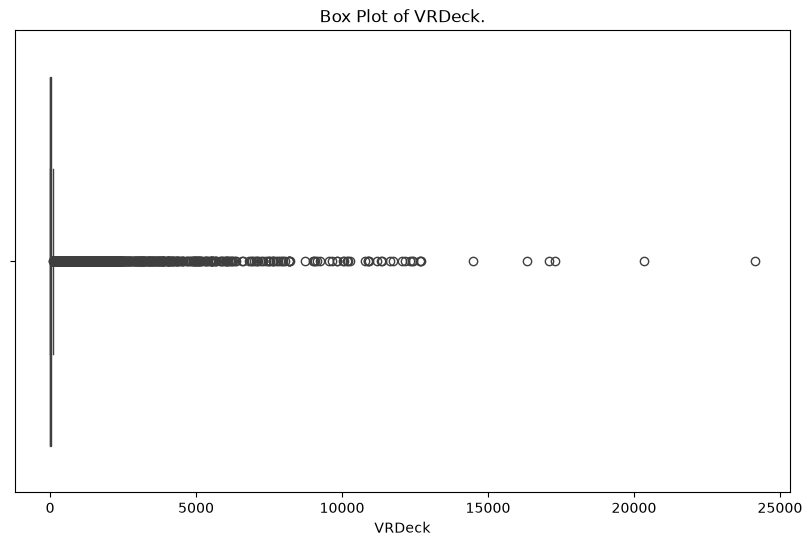

In [6]:
for col in numeric_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=df,
        x=col
    )
    plt.title(f"Box Plot of {col}.")
    plt.show()

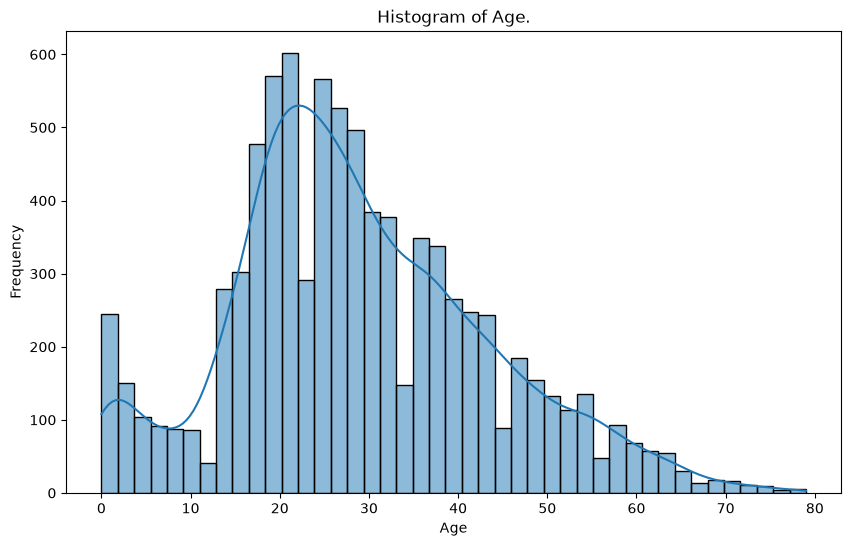

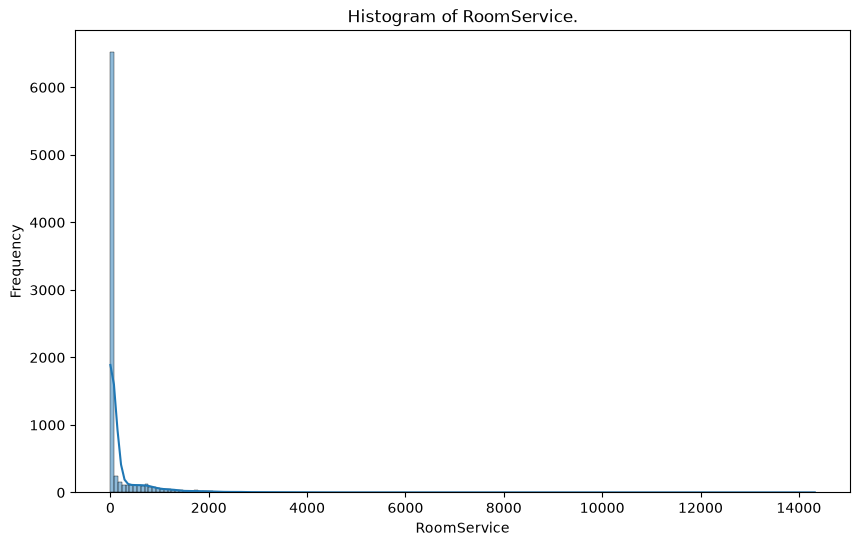

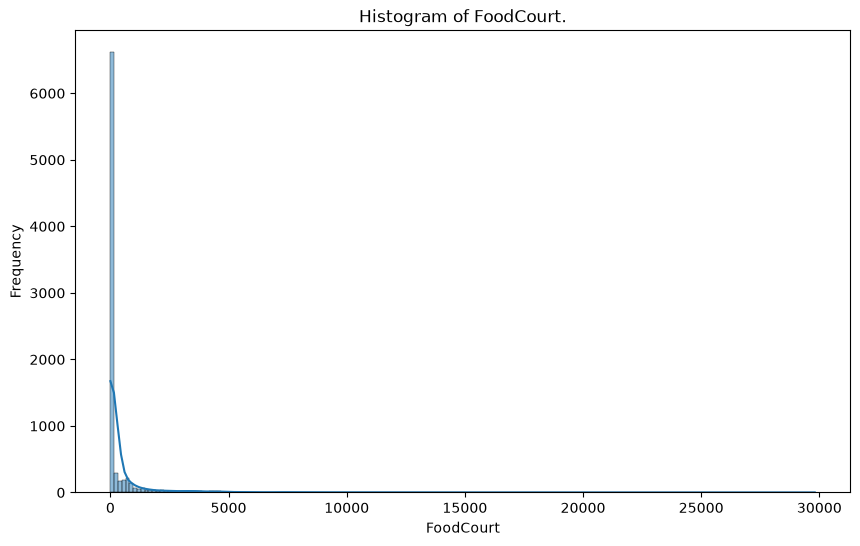

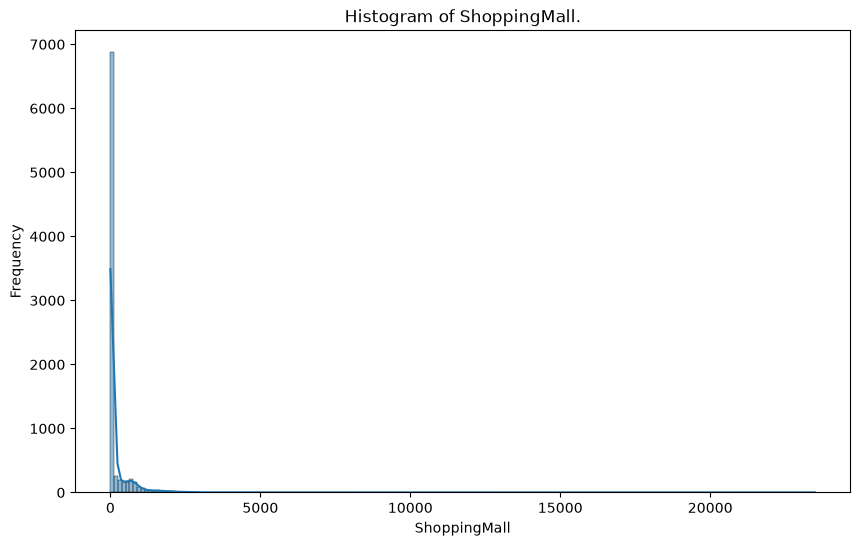

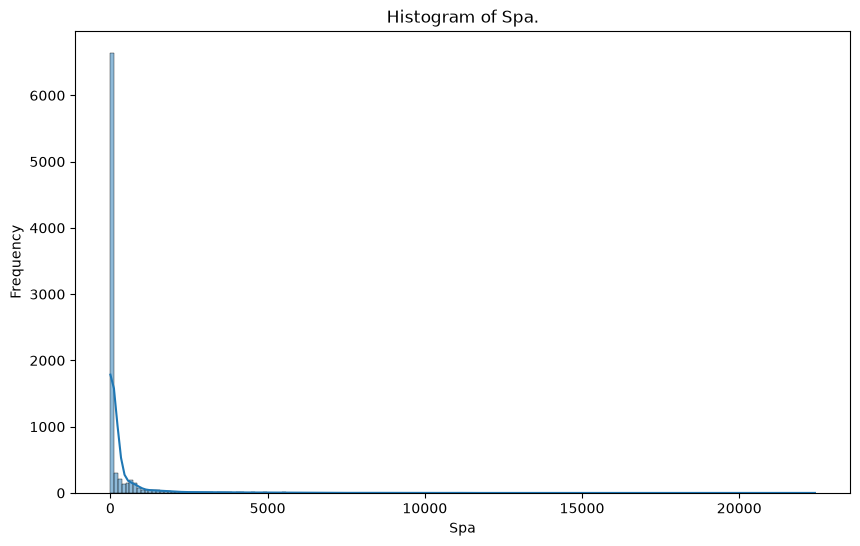

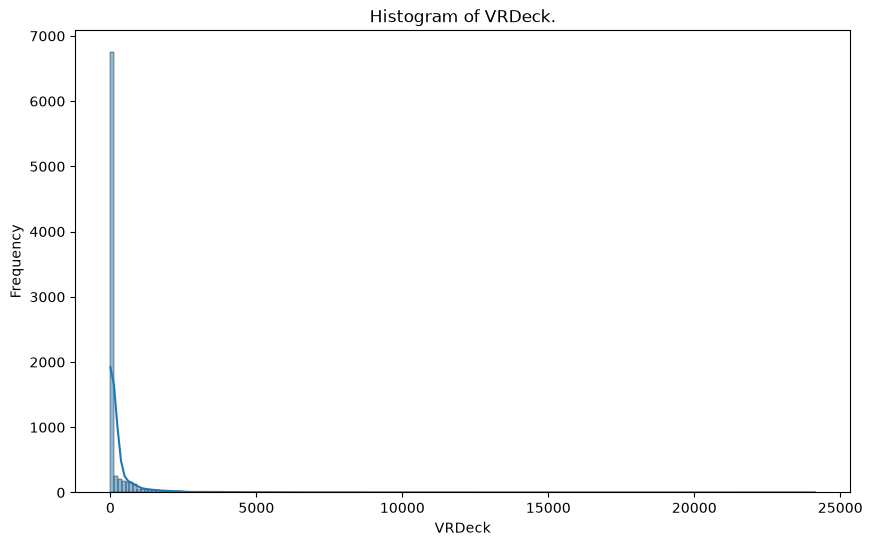

In [7]:
for col in numeric_cols:
    plt.figure(figsize=(10, 6))
    sns.histplot(
        data=df,
        x=col,
        kde=True
    )
    plt.title(f"Histogram of {col}.")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [8]:
display(df.head())

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [9]:
# data preprocessing

def preprocessing(data):
    df_clean = data.copy()

    # Cabin - The cabin number where the passenger is staying. 
    # Takes the form deck/num/side, where side can be either P for Port or S for Starboard.
    # Split Cabin into Deck, Cabin_num, and Side
    df_clean[['Deck', 'Cabin_num', 'Side']] = df_clean['Cabin'].str.split("/", expand=True) 

    # gather spend features
    spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

    # passengers inn CryoSleep are confined to their cabins in suspended animation, so they cannot spend money
    for col in spend_cols:
        df_clean.loc[df_clean['CryoSleep']==True, col] = df_clean.loc[df_clean['CryoSleep']==True, col].fillna(0)

    # to handle right-screwed from the outlier analysis
    for col in numeric_cols:
        upper_limit = df_clean[col].quantile(0.99)
        df_clean[col] = np.clip(df_clean[col], a_min=0, a_max=upper_limit)
        # caps any extreme outlier above the 99th percentile down to upper_limit
        # set a_min=0 to ensure no negative values exit

    # add new Total_Spend Feature
    df_clean['Total_Spend']=df_clean[spend_cols].sum(axis=1)

    # convert obj columns to str
    df_clean['CryoSleep'] = df_clean['CryoSleep'].astype('str')
    df_clean['VIP'] = df_clean['VIP'].astype('str')

    # drop the columns not needed by the model
    drop_cols = ['PassengerId', 'Name', 'Cabin', 'Cabin_num']
    df_clean = df_clean.drop(columns=drop_cols, errors='ignore')

    return df_clean



In [10]:
df_processed = preprocessing(df)

In [11]:
display(df_processed.head())

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Deck,Side,Total_Spend
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,B,P,0.0
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,F,S,736.0
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,5383.6,49.0,False,A,S,9051.6
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,A,S,5176.0
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,F,S,1091.0


In [12]:
print('\n--- Processed Columnns ---')
print(df_processed.columns)


--- Processed Columnns ---
Index(['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'RoomService',
       'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Transported', 'Deck',
       'Side', 'Total_Spend'],
      dtype='str')


In [13]:
print('\n--- Processed Data Info ---')
print(df_processed.info())


--- Processed Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HomePlanet    8492 non-null   str    
 1   CryoSleep     8476 non-null   str    
 2   Destination   8511 non-null   str    
 3   Age           8514 non-null   float64
 4   VIP           8490 non-null   str    
 5   RoomService   8580 non-null   float64
 6   FoodCourt     8580 non-null   float64
 7   ShoppingMall  8581 non-null   float64
 8   Spa           8575 non-null   float64
 9   VRDeck        8567 non-null   float64
 10  Transported   8693 non-null   bool   
 11  Deck          8494 non-null   str    
 12  Side          8494 non-null   str    
 13  Total_Spend   8693 non-null   float64
dtypes: bool(1), float64(7), str(6)
memory usage: 1.1 MB
None


In [14]:
print('\n--- Processed Data Missing Check ---')
print(df_processed.isnull().sum())


--- Processed Data Missing Check ---
HomePlanet      201
CryoSleep       217
Destination     182
Age             179
VIP             203
RoomService     113
FoodCourt       113
ShoppingMall    112
Spa             118
VRDeck          126
Transported       0
Deck            199
Side            199
Total_Spend       0
dtype: int64


In [15]:
# Seperate Features X and Target y

X = df_processed.drop(columns=['Transported'])
y = df_processed['Transported'].astype('int')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [16]:
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape: {y_test.shape}')

X_train shape: (6954, 13)
X_test shape: (1739, 13)
y_train shape: (6954,)
y_test shape: (1739,)


In [17]:
# ColumnTransformer setup

num_cols = X_train.select_dtypes(include='number').columns.tolist()
print(f"Numeric Columns: {num_cols}")

cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()
print(f"Category Columns: {cat_cols}")

# Numerical pipeline: Impute missing with median + RobustScaler
# RobustScaler is resistant to outliers
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Categorical pipeline: Impute missing with most frequent + One-Hot Encode
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])

# Combine using ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])


Numeric Columns: ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Total_Spend']
Category Columns: ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side']


In [18]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [19]:
# Approach 1
pipe_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectKBest(f_classif, k=15)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Approach 2
pipe_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectKBest(f_classif, k=18)),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Approach 3
pipe_gb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectFromModel(RandomForestClassifier(n_estimators=50, random_state=42))),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

In [20]:
# Compare models using 5-folds Cross Validation 

pipelines = {
    "Logistic Regression (SelectKBest)" : pipe_lr,
    "Random Forest Classifier (SelectKBest)" : pipe_rf,
    "Gradient Boosting Classifier (SelectFromModel)" : pipe_gb
}

print("\n--- Comparing Models using 5-folds Cross Validation ---")
for name, model in pipelines.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    print(f"{name}: Mean {cv_scores.mean():.4f} with std of {cv_scores.std():.4f}")



--- Comparing Models using 5-folds Cross Validation ---
Logistic Regression (SelectKBest): Mean 0.7926 with std of 0.0045
Random Forest Classifier (SelectKBest): Mean 0.7798 with std of 0.0098
Gradient Boosting Classifier (SelectFromModel): Mean 0.7896 with std of 0.0117


In [22]:
# Hyper Parameter Tuning
print(list(pipe_lr.get_params().keys()))

['memory', 'steps', 'transform_input', 'verbose', 'preprocessor', 'feature_selection', 'classifier', 'preprocessor__n_jobs', 'preprocessor__remainder', 'preprocessor__sparse_threshold', 'preprocessor__transformer_weights', 'preprocessor__transformers', 'preprocessor__verbose', 'preprocessor__verbose_feature_names_out', 'preprocessor__num', 'preprocessor__cat', 'preprocessor__num__memory', 'preprocessor__num__steps', 'preprocessor__num__transform_input', 'preprocessor__num__verbose', 'preprocessor__num__imputer', 'preprocessor__num__scaler', 'preprocessor__num__imputer__add_indicator', 'preprocessor__num__imputer__copy', 'preprocessor__num__imputer__fill_value', 'preprocessor__num__imputer__keep_empty_features', 'preprocessor__num__imputer__missing_values', 'preprocessor__num__imputer__strategy', 'preprocessor__num__scaler__copy', 'preprocessor__num__scaler__quantile_range', 'preprocessor__num__scaler__unit_variance', 'preprocessor__num__scaler__with_centering', 'preprocessor__num__scal

In [23]:
print(list(pipe_rf.get_params().keys()))

['memory', 'steps', 'transform_input', 'verbose', 'preprocessor', 'feature_selection', 'classifier', 'preprocessor__n_jobs', 'preprocessor__remainder', 'preprocessor__sparse_threshold', 'preprocessor__transformer_weights', 'preprocessor__transformers', 'preprocessor__verbose', 'preprocessor__verbose_feature_names_out', 'preprocessor__num', 'preprocessor__cat', 'preprocessor__num__memory', 'preprocessor__num__steps', 'preprocessor__num__transform_input', 'preprocessor__num__verbose', 'preprocessor__num__imputer', 'preprocessor__num__scaler', 'preprocessor__num__imputer__add_indicator', 'preprocessor__num__imputer__copy', 'preprocessor__num__imputer__fill_value', 'preprocessor__num__imputer__keep_empty_features', 'preprocessor__num__imputer__missing_values', 'preprocessor__num__imputer__strategy', 'preprocessor__num__scaler__copy', 'preprocessor__num__scaler__quantile_range', 'preprocessor__num__scaler__unit_variance', 'preprocessor__num__scaler__with_centering', 'preprocessor__num__scal

In [24]:
print(list(pipe_gb.get_params().keys()))

['memory', 'steps', 'transform_input', 'verbose', 'preprocessor', 'feature_selection', 'classifier', 'preprocessor__n_jobs', 'preprocessor__remainder', 'preprocessor__sparse_threshold', 'preprocessor__transformer_weights', 'preprocessor__transformers', 'preprocessor__verbose', 'preprocessor__verbose_feature_names_out', 'preprocessor__num', 'preprocessor__cat', 'preprocessor__num__memory', 'preprocessor__num__steps', 'preprocessor__num__transform_input', 'preprocessor__num__verbose', 'preprocessor__num__imputer', 'preprocessor__num__scaler', 'preprocessor__num__imputer__add_indicator', 'preprocessor__num__imputer__copy', 'preprocessor__num__imputer__fill_value', 'preprocessor__num__imputer__keep_empty_features', 'preprocessor__num__imputer__missing_values', 'preprocessor__num__imputer__strategy', 'preprocessor__num__scaler__copy', 'preprocessor__num__scaler__quantile_range', 'preprocessor__num__scaler__unit_variance', 'preprocessor__num__scaler__with_centering', 'preprocessor__num__scal

In [ ]:
# Setting Param_grid for LogisticRegression
param_grid_lr = {
    "feature_selection__k": [15, 20, 25, 'all'],
    "classifier__C": [0.01, 0.1, 1.0, 10.0], # controls regularization (penalty for complex weights)
    "classifier__solver": ['lbfgs', 'liblinear'] # mathematical optimization algorithms
}

# Setting Param_grid for RandomForestClassifier
param_grid_rf = {
    "feature_selection__k": [18, 24, 'all'],
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [6, 8, 10],
    "classifier__min_samples_split": [5, 10]
}

# Setting Param_grid for GradientBoostingClassifier
param_grid_gb = {
    "feature_selection__threshold": ['mean', '0.5*mean', -np.inf],
    "classifier__n_estimators": [100, 150, 200], # Number of sequential trees
    "classifier__learning_rate": [0.05, 0.1, 0.2],
    "classifier__max_depth": [3, 4, 5]
}

In [ ]:
grids ={
    "Tuned LogisticRegression": GridSearchCV(pipe_lr, param_grid_lr, cv=5, scoring="accuracy", n_jobs=-1),
    "Tuned RandomForestClassifier": GridSearchCV(pipe_rf, param_grid_rf, cv=5, scoring="accuracy", n_jobs=-1),
    "Tuned GradientBoostingClassifier": GridSearchCV(pipe_gb, param_grid_gb, cv=5, scoring="accuracy", n_jobs=-1)
}